# Wilkinson ideal power divider

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import skrf as rf
from skrf.circuit import Circuit

rf.stylely()

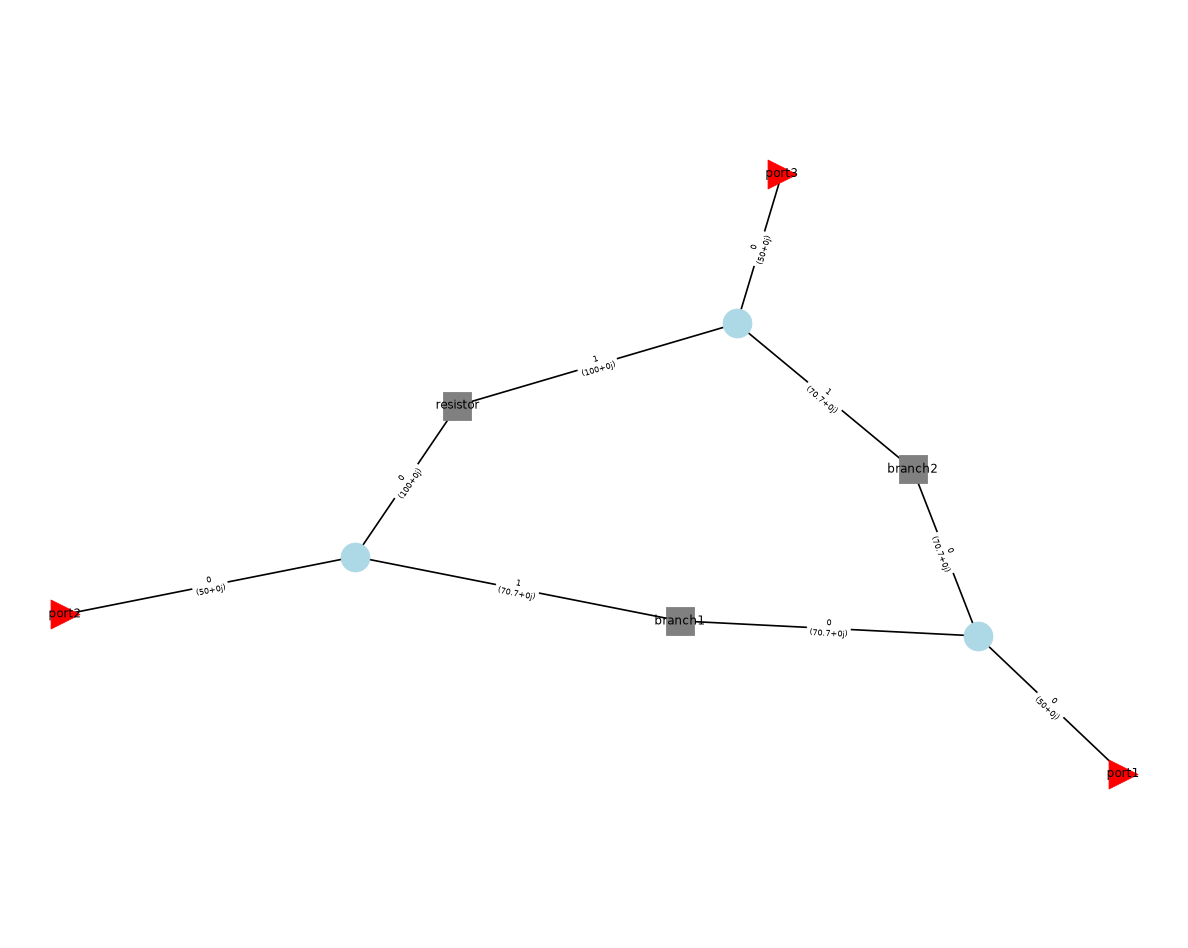

In [2]:
# Frequency band
freq = rf.Frequency(start=140, stop=190, npoints=501, unit='MHz')

# impedance of ports
z0_ports = 50

# Resistor
R = 100
line_resistor = rf.media.DefinedGammaZ0(frequency=freq, z0=R)
resistor = line_resistor.resistor(R, name='resistor')

# branches
z0_branches = np.sqrt(2)*z0_ports
beta = freq.w/rf.constants.c
line_branches = rf.media.DefinedGammaZ0(frequency=freq, z0=z0_branches, gamma=0+beta*1j)

d = line_branches.theta_2_d(90, deg=True)  # @ 90°(lambda/4)@ 1 GHz is ~ 75 mm
branch1 = line_branches.line(d, unit='m', name='branch1')
branch2 = line_branches.line(d, unit='m', name='branch2')

# Ports
port1 = Circuit.Port(freq, name='port1', z0=50)
port2 = Circuit.Port(freq, name='port2', z0=50)
port3 = Circuit.Port(freq, name='port3', z0=50)

# Connection setup
connections = [
    [(port1, 0), (branch1, 0), (branch2, 0)],
    [(port2, 0), (branch1, 1), (resistor, 0)],
    [(port3, 0), (branch2, 1,), (resistor, 1)]
]

# Build circuit
C_ideal = Circuit(connections)
# Verify the construction
C_ideal.plot_graph(network_labels=True, edge_labels=True, port_labels=True, port_fontize=2)

L = 68.21 nH | C = 13.64 pF


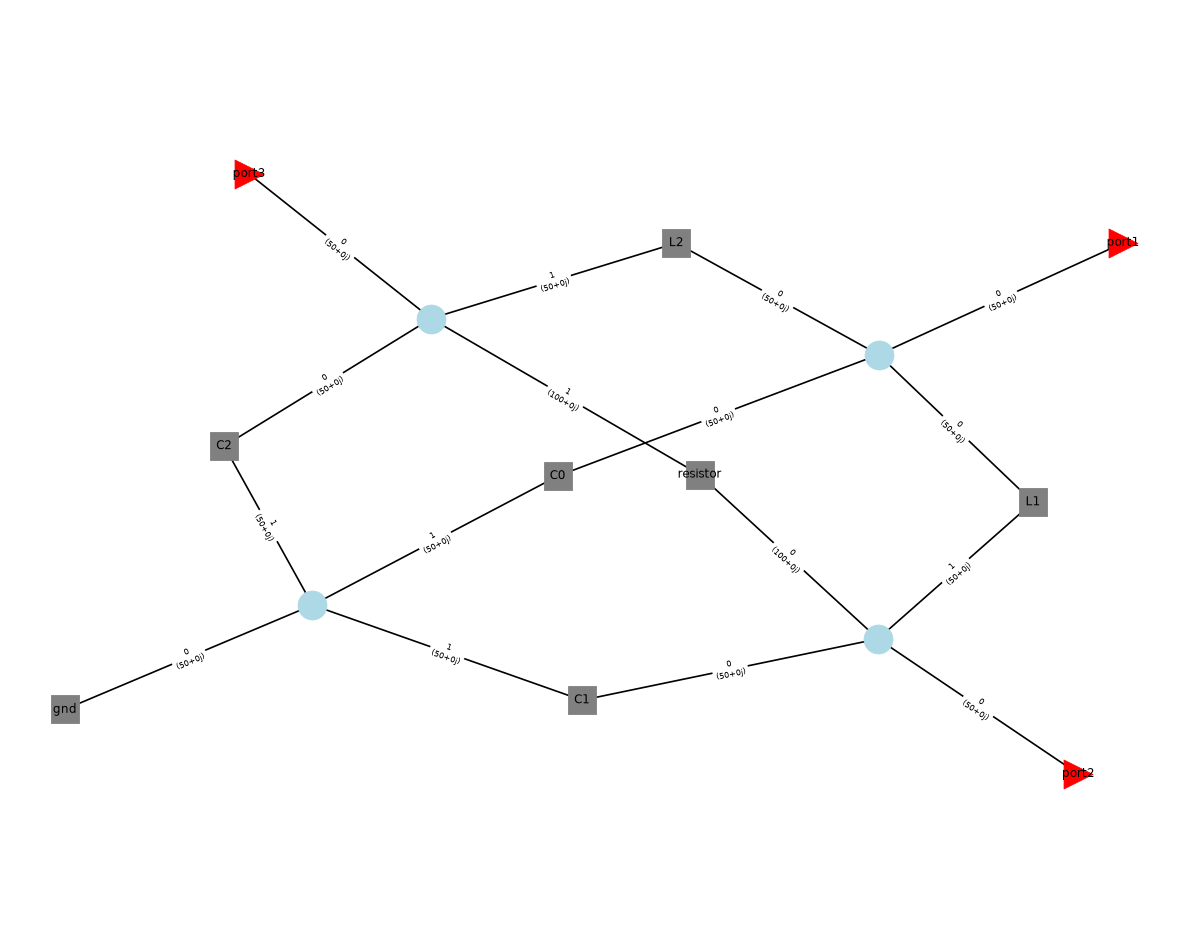

In [6]:
# Circuit parameters
f0 = 165e6
w0 = 2*np.pi*f0
L = z0_branches/w0
C = 1/(w0*z0_branches)
print(f"L = {L*1e9:.2f} nH | C = {C*1e12:.2f} pF")

lumped = rf.media.DefinedGammaZ0(frequency=freq, z0=z0_ports)

R = 100
res_media = rf.media.DefinedGammaZ0(frequency=freq, z0=R)
resistor = res_media.resistor(R, name='resistor')

C0 = lumped.capacitor(2*C, name='C0')

# Equivalent branches
L1 = lumped.inductor(L, name='L1')
C1 = lumped.capacitor(C, name='C1')

L2 = lumped.inductor(L, name='L2')
C2 = lumped.capacitor(C, name='C2')

# GND
gnd = Circuit.Ground(freq, name='gnd', z0=z0_ports)

# Ports
port1 = Circuit.Port(freq, name='port1', z0=50)
port2 = Circuit.Port(freq, name='port2', z0=50)
port3 = Circuit.Port(freq, name='port3', z0=50)

connections = [
    [(port1, 0), (C0, 0), (L1, 0), (L2, 0)],
    [(port2, 0), (L1, 1), (C1, 0), (resistor, 0)],
    [(port3, 0), (L2, 1), (C2, 0), (resistor, 1)],
    [(gnd,0), (C0, 1), (C1, 1), (C2, 1)]
]


C_lumped = Circuit(connections)
# Verify the construction
C_lumped.plot_graph(network_labels=True, edge_labels=True, port_labels=True, port_fontize=2)

Section B components ZB: 83.35 | CB: 11.57 pF | LB: 80.40 nH | RB: 93.22 Ohm
Section A components ZA: 59.99 | CA: 16.08 pF | LA: 57.86 nH | RA: 265.81 Ohm


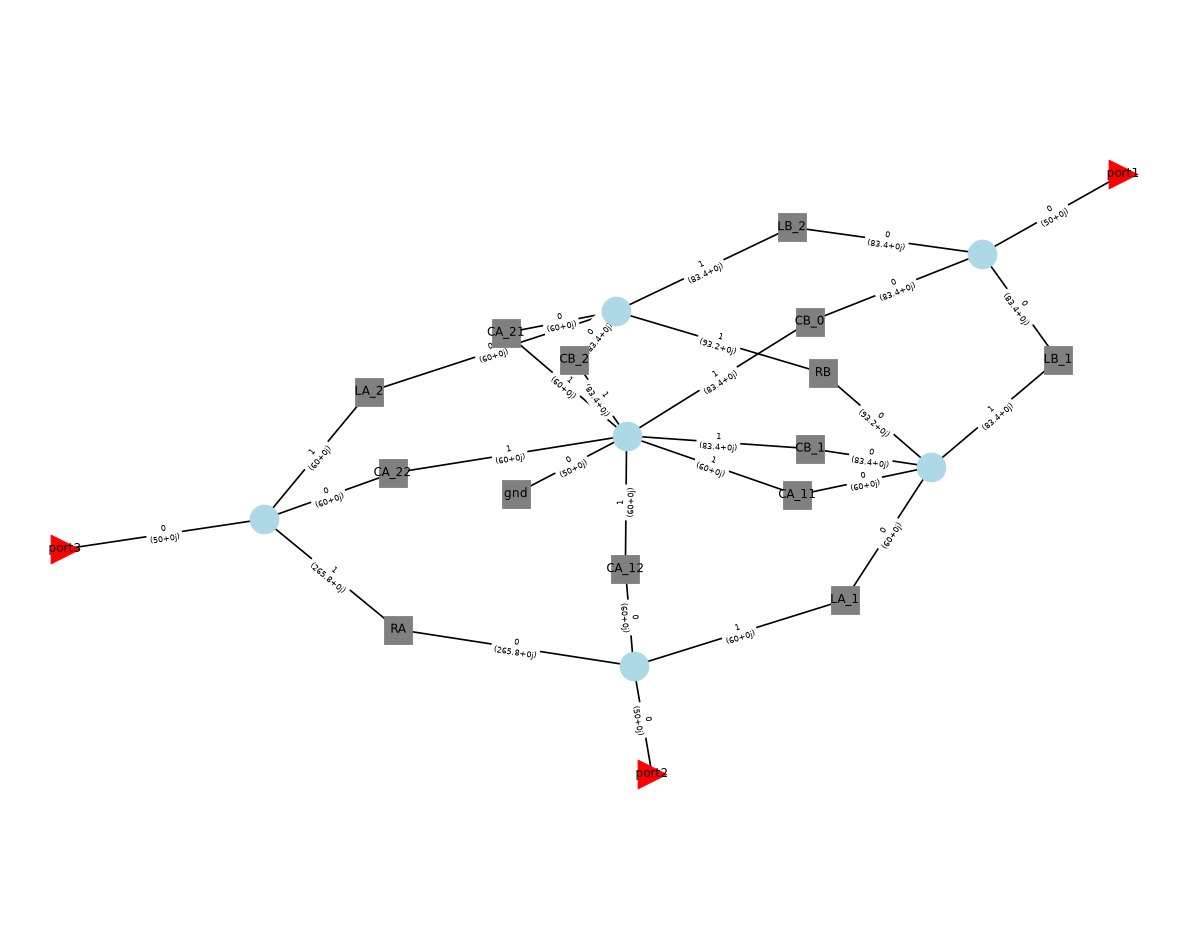

In [32]:
# Two sections Wilkinson lumped divider
z1_n = 1.1998
r1_n = 5.3163
z2_n = 1.6670
r2_n = 1.8643

# Section B
ZB = z2_n * z0_ports
CB = 1/(w0 * ZB)
LB = ZB / w0
RB = r2_n * z0_ports
print(f"Section B components ZB: {ZB:.2f} | CB: {CB*1e12:.2f} pF | LB: {LB*1e9:.2f} nH | RB: {RB:.2f} Ohm")

# Section 1
ZA = z1_n * z0_ports
CA = 1/(w0*ZA)
LA = ZA/w0
RA = r1_n*z0_ports
print(f"Section A components ZA: {ZA:.2f} | CA: {CA*1e12:.2f} pF | LA: {LA*1e9:.2f} nH | RA: {RA:.2f} Ohm")



two_section = rf.media.DefinedGammaZ0(frequency=freq, z0=z0_ports)

# B-Branches
b_section = rf.media.DefinedGammaZ0(frequency=freq, z0=ZB)
B_L1 = b_section.inductor(LB, name='LB_1')
B_C1 = b_section.capacitor(CB, name='CB_1')

B_L2 = b_section.inductor(LB, name='LB_2')
B_C2 = b_section.capacitor(CB, name='CB_2')

B_C0 = b_section.capacitor(2*CB, name='CB_0')

b_res_media = rf.media.DefinedGammaZ0(frequency=freq, z0=RB)
B_R = b_res_media.resistor(RB, name='RB')

# A-branches
a_section = rf.media.DefinedGammaZ0(frequency=freq, z0=ZA)
A_C11 = a_section.capacitor(CA, name='CA_11')
A_L1 = a_section.inductor(LA, name='LA_1')
A_C12 = a_section.capacitor(CA, name='CA_12')

A_C21 = a_section.capacitor(CA, name='CA_21')
A_L2 = a_section.inductor(LA, name='LA_2')
A_C22 = a_section.capacitor(CA, name='CA_22')

a_res_media = rf.media.DefinedGammaZ0(frequency=freq, z0=RA)
A_R = a_res_media.resistor(RA, name='RA')

# GND
gnd = Circuit.Ground(freq, name='gnd', z0=z0_ports)

# Ports
port1 = Circuit.Port(freq, name='port1', z0=50)
port2 = Circuit.Port(freq, name='port2', z0=50)
port3 = Circuit.Port(freq, name='port3', z0=50)

connections = [
    [(port1, 0), (B_C0, 0), (B_L1, 0), (B_L2, 0)],
    [(B_R, 0), (B_L1, 1), (B_C1, 0), (A_C11, 0), (A_L1, 0)],
    [(B_R, 1), (B_L2, 1), (B_C2, 0), (A_C21, 0), (A_L2, 0)],
    [(A_L1, 1), (A_C12, 0), (A_R, 0), (port2, 0)],
    [(A_L2, 1), (A_C22, 0), (A_R, 1), (port3, 0)],
    [(gnd, 0), (B_C0, 1), (B_C1, 1), (B_C2, 1), (A_C11, 1), (A_C12, 1), (A_C21,1), (A_C22,1)]
]

C_two_section = Circuit(connections)
# # Verify the construction
C_two_section.plot_graph(network_labels=True, edge_labels=True, port_labels=True, port_fontize=2)


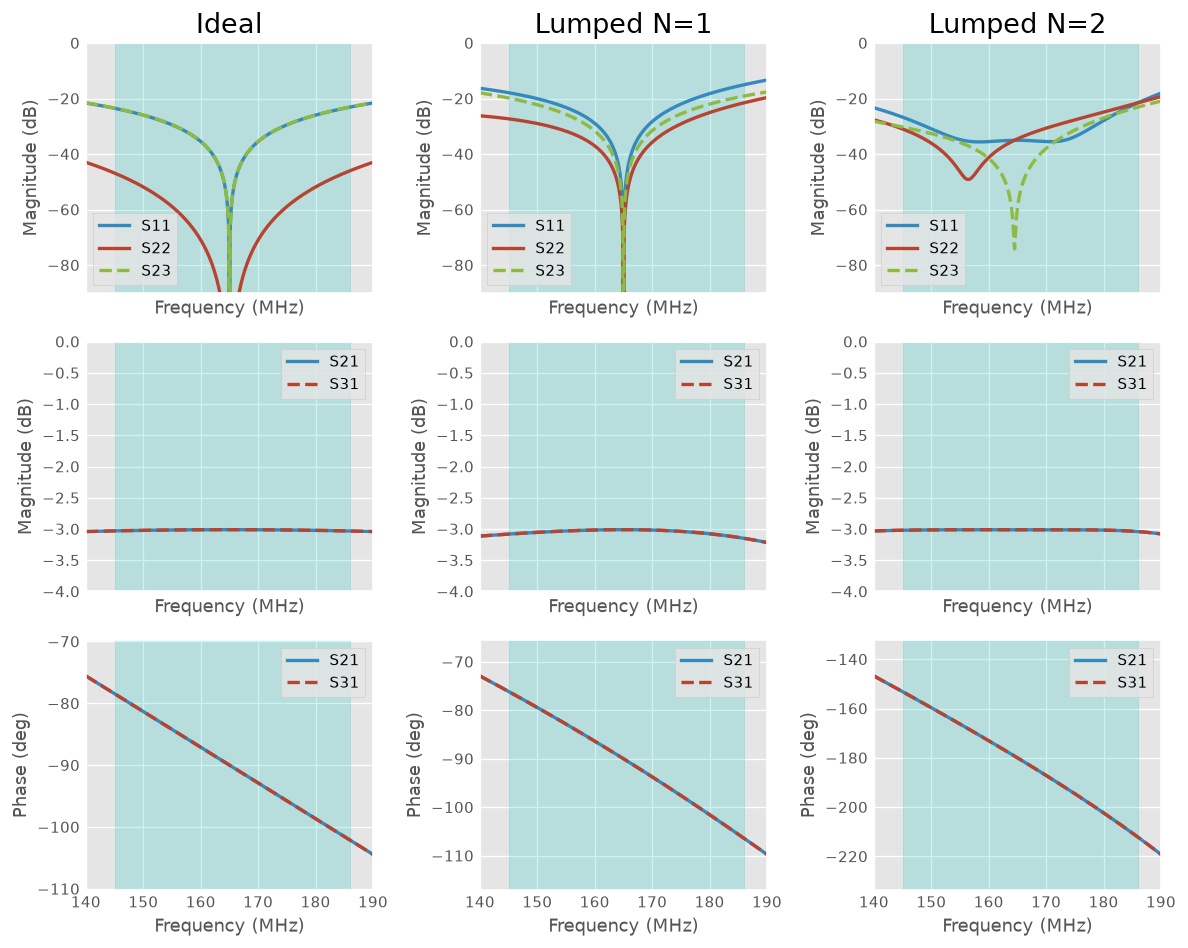

In [31]:
# Plot frequency response

fig, axs = plt.subplots(3, 3, sharex=True, figsize=(10,8))


C_ideal.network.plot_s_db(ax=axs[0,0], m=0, n=0, lw=2) #s11
C_ideal.network.plot_s_db(ax=axs[0,0], m=1, n=1, lw=2) #s22
C_ideal.network.plot_s_db(ax=axs[0,0], m=1, n=2, ls='--', lw=2) #s23
axs[0,0].set_ylim(-90, 0)
C_ideal.network.plot_s_db(ax=axs[1,0], m=1, n=0, lw=2) #s21
C_ideal.network.plot_s_db(ax=axs[1,0], m=2, n=0, ls='--', lw=2) #s31
axs[1,0].set_ylim(-4, 0)
C_ideal.network.plot_s_deg_unwrap(ax=axs[2,0], m=1, n=0, lw=2)
C_ideal.network.plot_s_deg_unwrap(ax=axs[2,0], m=2, n=0, ls='--', lw=2)

# axs[0,0].set_title("Ideal Wilkinson Divider @ 165MHz")
axs[0,0].set_title("Ideal")

C_lumped.network.plot_s_db(ax=axs[0,1], m=0, n=0, lw=2) #s11
C_lumped.network.plot_s_db(ax=axs[0,1], m=1, n=1, lw=2) # s22
C_lumped.network.plot_s_db(ax=axs[0,1], m=1, n=2, ls='--', lw=2) # S23
axs[0, 1].set_ylim(-90,0)
C_lumped.network.plot_s_db(ax=axs[1,1], m=1, n=0, lw=2)
C_lumped.network.plot_s_db(ax=axs[1,1], m=2, n=0, ls='--', lw=2)
axs[1,1].set_ylim(-4,0)
C_lumped.network.plot_s_deg_unwrap(ax=axs[2,1], m=1, n=0, lw=2)
C_lumped.network.plot_s_deg_unwrap(ax=axs[2,1], m=2, n=0, ls='--', lw=2)

# axs[0,1].set_title("Lumped Wilkinson Divider @ 165MHz")
axs[0,1].set_title("Lumped N=1")


C_two_section.network.plot_s_db(ax=axs[0,2], m=0, n=0, lw=2) #s11
C_two_section.network.plot_s_db(ax=axs[0,2], m=1, n=1, lw=2) # s22
C_two_section.network.plot_s_db(ax=axs[0,2], m=1, n=2, ls='--', lw=2) # S23
axs[0, 2].set_ylim(-90,0)
C_two_section.network.plot_s_db(ax=axs[1,2], m=1, n=0, lw=2)
C_two_section.network.plot_s_db(ax=axs[1,2], m=2, n=0, ls='--', lw=2)
axs[1,2].set_ylim(-4,0)
C_two_section.network.plot_s_deg_unwrap(ax=axs[2,2], m=1, n=0, lw=2)
C_two_section.network.plot_s_deg_unwrap(ax=axs[2,2], m=2, n=0, ls='--', lw=2)

# axs[0,1].set_title("Lumped Wilkinson Divider @ 165MHz")
axs[0,2].set_title("Lumped N=2")


# Mark the areas of interest
for i in range(3):
    for j in range(3):
        axs[i, j].axvspan(145e6, 186e6, color='c', alpha=0.2)


fig.tight_layout()